In [1]:
import numpy as np
import pandas as pd
from numpy.random import randn
from scipy import stats
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns 

**dataset of seaborn and make dataframe**

In [3]:
tips = sns.load_dataset('tips')

In [4]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


**plot tips Vs. total bill**

**regression plot**

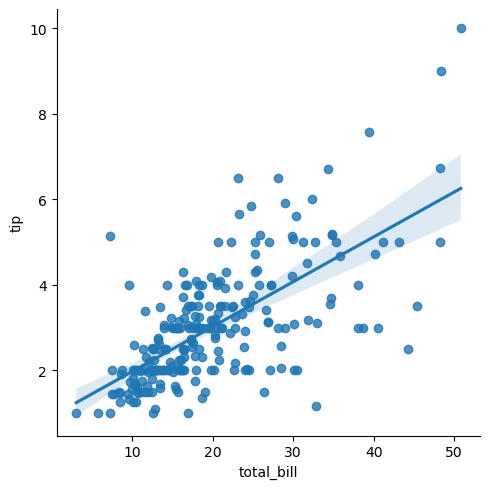

In [6]:
sns.lmplot(tips,y='tip',x='total_bill')

**first order trend line**

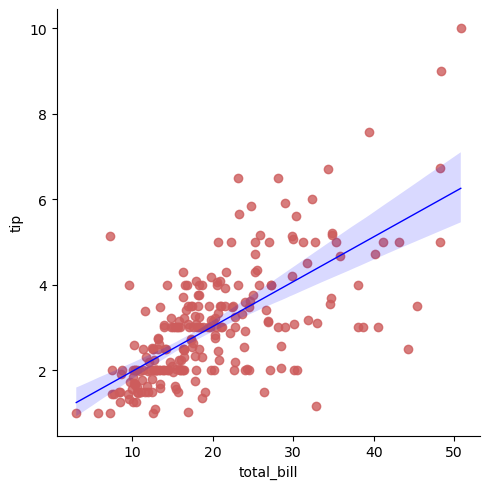

In [26]:
sns.lmplot(tips,y='tip',x='total_bill',
          scatter_kws={'marker':'o','color':'indianred'},
          line_kws={'linewidth':1,'color':'blue'})

**order**

**different fit on data**

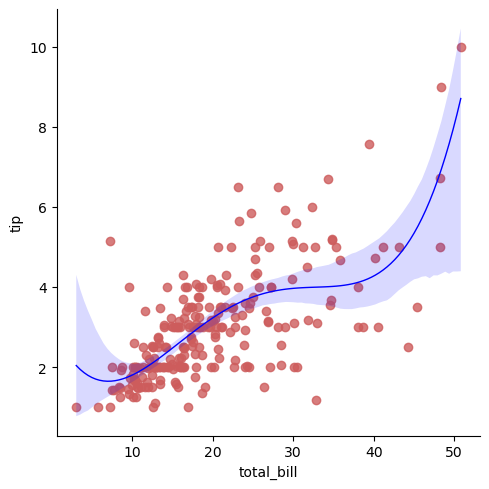

In [35]:
sns.lmplot(tips,y='tip',x='total_bill',order=4,
          scatter_kws={'marker':'o','color':'indianred'},
          line_kws={'linewidth':1,'color':'blue'})

**just scatter and not linear regression**

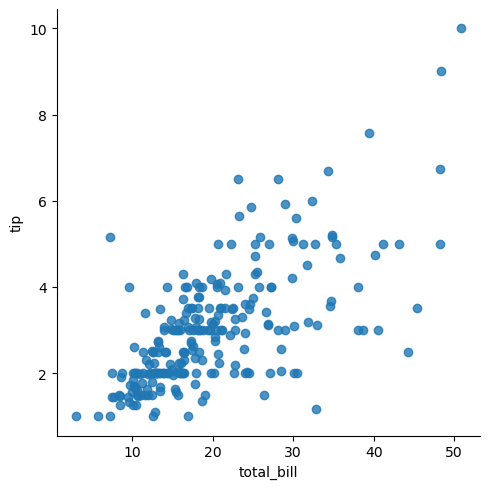

In [40]:
sns.lmplot(tips,x='total_bill',y='tip',fit_reg=False)

**lm plots on discrete variables**

In [43]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [45]:
# percentage of total bill
tips['tip_pect'] = 100*(tips['tip']/tips['total_bill'])

In [47]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size,tip_pect
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765


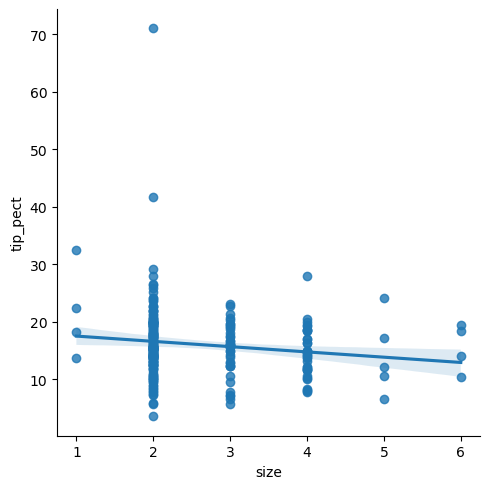

In [49]:
sns.lmplot(tips,x='size',y='tip_pect')

**Jitter:** The unwanted variation in the timing of a signal or event from its ideal or expected timing.

Ideal:   |----10ms----|----10ms----|----10ms----|

Actual:  |---9.8ms----|----10.2ms--|----9.9ms

we use it for more easy to read 

Note : data won't change just the location of them will change in plot

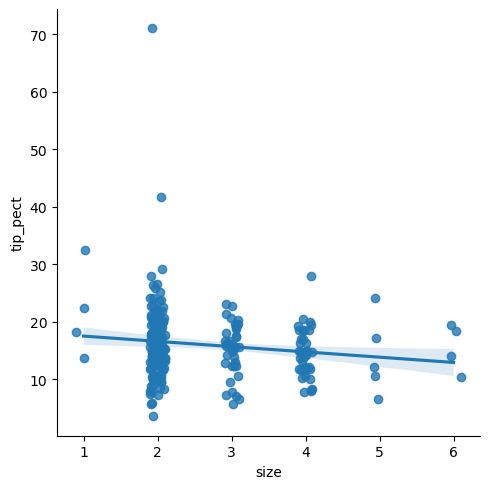

In [57]:
sns.lmplot(tips,x='size',y='tip_pect',x_jitter=.1)

**estimate tendency of each bin**

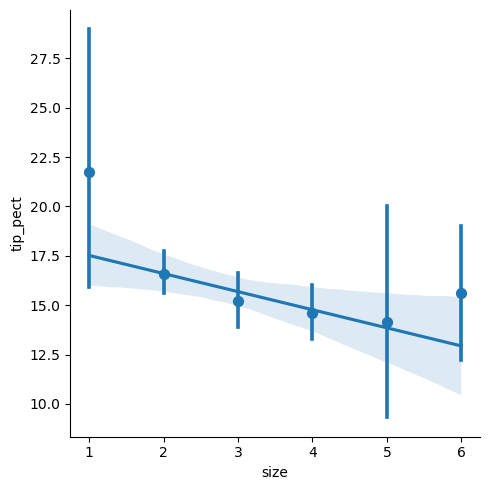

In [77]:
sns.lmplot(tips,x='size',y='tip_pect',x_estimator=np.mean)

**hue facet**

**define subsets along column**

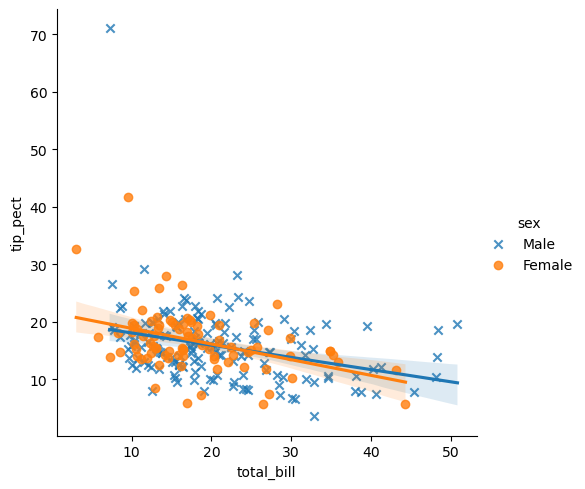

In [71]:
# تفکیک رنگی برای sex column
sns.lmplot(tips,x='total_bill',y='tip_pect',hue='sex',markers=['x','o'])

**giving tips base on the day**

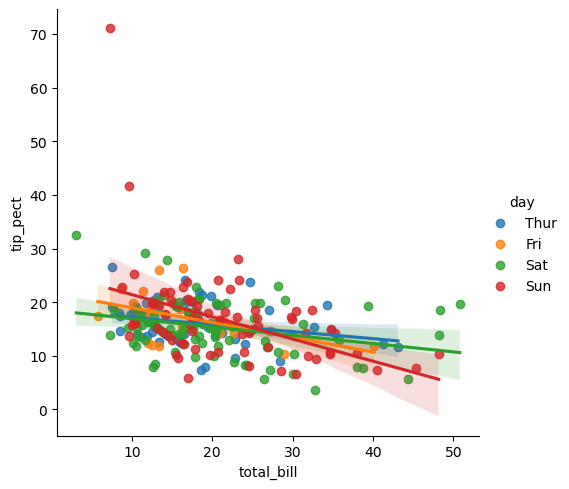

In [82]:
sns.lmplot(tips,x='total_bill',y='tip_pect',hue='day')

**local regression model fitting**

http://en.wikipedia.org/wiki/Local_regression

**Linear Regression:**

One global line is fitted to all data points.

**Local Regression:**

Small local models are fitted to nearby data points, producing a smooth curve.

**methods**
1. LOESS — Locally Estimated Scatterplot Smoothing
   
3. LOWESS — Locally Weighted Scatterplot Smoothing

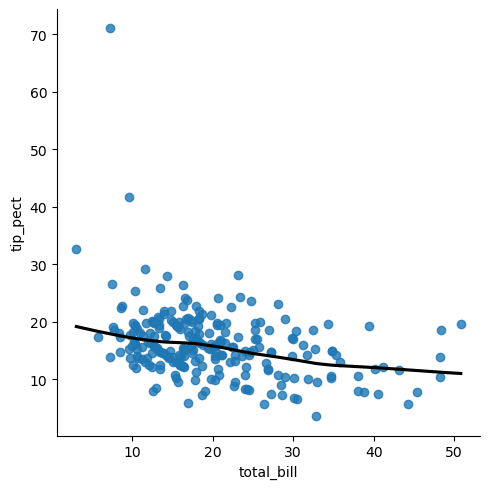

In [89]:
sns.lmplot(tips,x='total_bill',y='tip_pect',lowess=True,line_kws={'color':'black'})

**regplot** 

**regplot:** An axes-level function used to create a regression plot. It can be added to an existing Axes or subplot using `ax=`.

**lmplot:** A figure-level function for regression plots. It is built on top of `regplot` and is useful for creating multiple regression plots using `row` and `col`.

**Main difference:**
`regplot` → works on an existing Axes.
`lmplot` → creates and manages the Figure and subplots.


<Axes: xlabel='total_bill', ylabel='tip_pect'>

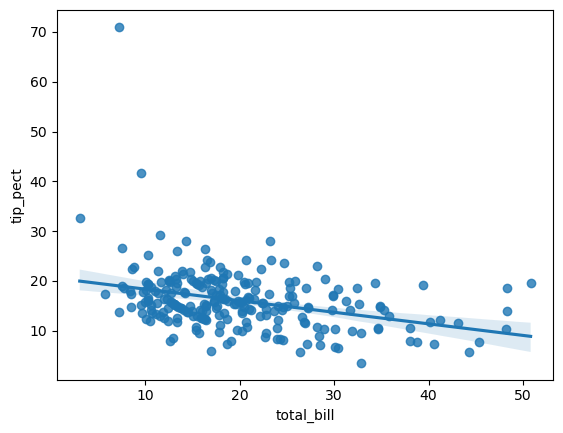

In [93]:
sns.regplot(tips,x='total_bill',y='tip_pect')

**creating figure of two subplot**

<Axes: >

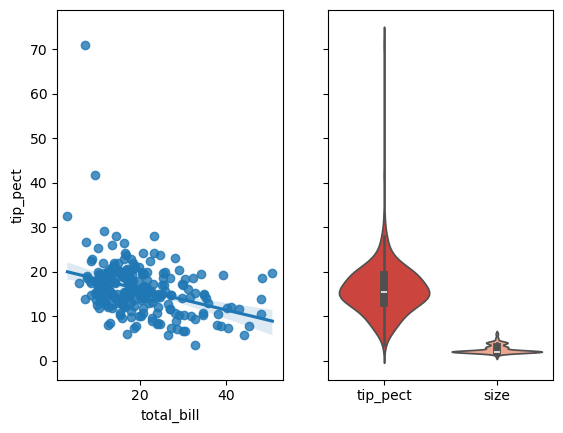

In [118]:
# sharey=True: means y axis is commen to both and uniform scale
fig, (axis1,axis2) = plt.subplots(1,2,sharey=True)
#
sns.regplot(tips,x='total_bill',y='tip_pect',ax=axis1)
sns.violinplot([tips['tip_pect'],tips['size']], palette='Reds_r',ax=axis2)